# 01｜親手理解你的 FYP：CSV → 分析 → 圖表 → 模型
日期：2026-10-16。這是教學及既有實驗重現，不是新的正式研究結果，也不是報告正文。

**今天要完成的事：**自己讀取資料、解釋缺失與分布、生成三張圖，然後實際訓練一個模型，與既有研究的同一折預測比較。

- 先完成第 1–5 節（約 20–30 分鐘），再做第 6–10 節。可分兩次學習。
- 點選 code cell，按 **Shift+Enter** 執行及移到下一格。左側 `[*]` 表示仍在運算。
- 先按順序執行；要清除記憶中的變數並重來，可選 **Kernel → Restart Kernel and Run All Cells**。
- 圖表標籤使用英文，避免不同電腦的中文字型問題；解說用中文。
- 教學使用已核對的 Android **train 分區**。不讀取 calibration/test 的性能，不更新 app，也不訓練 KNN。
- 此檔由 AI 協助建立。請自己執行、修改練習、理解及記錄協助；它不代表你已獨立寫完所有研究程式。

## 1. 載入 Python 工具
`pandas` 處理資料表；`numpy` 處理數值陣列；`matplotlib` 畫圖；之後用 `scikit-learn` 訓練模型。

以下路徑及 hash 檢查是本專案的保護設定：確認讀到已核對版本。你先理解用途，不需立即背熟。若找不到資料，請先確認這份 Notebook 位於 `My_FYP/Program/notebooks/`，並透過 `START_WALKTHROUGH.cmd` 開啟。

In [3]:
from pathlib import Path
import hashlib
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/analysis_v1.json").exists()), None)
if ROOT is None:
    raise RuntimeError("請在 Program 或 Program/notebooks 內開啟 Notebook。")

OUT = ROOT / "reports/2026-10-16/walkthrough_v1"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

def sha256(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

guarded = {}
def verified_path(relative, expected_hash):
    path = ROOT / relative
    if not path.exists():
        raise FileNotFoundError(f"缺少本機資料：{path}；請勿自行重新切分取代它。")
    actual = sha256(path)
    assert actual == expected_hash, f"檔案版本不同：{relative}"
    guarded[relative] = actual
    return path

analysis = read_json(verified_path(
    "reports/2026-10-06/analysis_v1/manifest.json",
    "5f3f341ed1c45fbca703995d95d4eca46d54d1af75e69677e15308d20aed12a6"))
for relative, expected_hash in analysis["dependencies"].items():
    verified_path(relative, expected_hash)
assert sklearn.__version__ == "1.9.1" and pd.__version__ == "3.0.6", "請使用 walkthrough_v1 環境"
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})
print("Python:", sys.executable)
print("Program:", ROOT)
print("輸出位置:", OUT)

Python: F:\HKBU_Y4\FYP\My_FYP\Program\experiments\walkthrough_v1\.venv\Scripts\python.exe
Program: F:\HKBU_Y4\FYP\My_FYP\Program
輸出位置: F:\HKBU_Y4\FYP\My_FYP\Program\reports\2026-10-16\walkthrough_v1


## 2. 用 `pd.read_csv()` 讀取資料
這就是課堂常見的「load CSV」。先用已整理、提供給 Power BI 的 CSV，較容易理解。

**它不是原始 Kaggle CSV。**原始清理程式在 `src/data/clean_candidates.py`；這份匯出來自固定研究資料。今天先學會使用及檢查它，不重新改寫研究清理規則。

`DataFrame` 可以看作有欄名的資料表；`.shape` 是「列數、欄數」，`.head()` 顯示最前幾列。

In [4]:
powerbi_manifest = read_json(ROOT / "reports/2026-10-11/lecture_review/powerbi_export_verification.json")
csv_relative = "data/processed/powerbi_v1/mobile_games.csv"
csv_path = verified_path(csv_relative, powerbi_manifest["outputs"][csv_relative]["sha256"])

df = pd.read_csv(csv_path, dtype={"app_id": "string"},
                 keep_default_na=False, na_values=[""])
assert len(df) == 221806
assert df["app_id"].is_unique
print("資料表大小：", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

資料表大小： (221806, 14)


,app_id,target_tier,tier_order,age_days,age_band,age_band_order,category,content_rating,price_usd,free,ad_supported,in_app_purchases,price_usd_unavailable,free_unavailable
0,BKE.blom.com,M2_1k_to_under_100k,2,3821,1095+ days,4,Puzzle,Everyone,0.00,Yes,No,No,No,No
1,ExtremeDevelopers.Exorcist,M1_under_1k,1,3397,1095+ days,4,Arcade,Teen,9.99,No,No,No,No,No
2,ExtremeDevelopers.NeedforDrift,M3_100k_plus,3,3271,1095+ days,4,Racing,Everyone,0.00,Yes,No,Yes,No,No
3,LASroCd.game,M1_under_1k,1,3326,1095+ days,4,Arcade,Everyone,0.00,Yes,No,No,No,No
4,LiborVasa.Ships,M3_100k_plus,3,3667,1095+ days,4,Puzzle,Everyone,0.00,Yes,No,No,No,No


,dtype
app_id,string
target_tier,str
tier_order,int64
age_days,int64
age_band,str
age_band_order,int64
category,str
content_rating,str
price_usd,float64
free,str


## 3. 檢查缺失及「未知」
`isna()` 找出空值，`sum()` 計算各欄空值數量。`value_counts()` 計算每個值出現多少次。

**注意：**文字 `Unknown` 不一定是 Pandas 的空值；CSV 的 `free` 是顯示用文字，不要直接把字串轉成 `bool`。本研究保留「免費／付費／未知」，不把未知改成付費或零價格。

先預測：`price_usd` 會否每列都有數值？`free` 只有兩種值嗎？

In [5]:
missing = pd.DataFrame({
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(3)
}).sort_values("missing_n", ascending=False)
display(missing)
display(df["free"].value_counts(dropna=False).rename("n").to_frame())
display(df[["age_days", "price_usd"]].describe())
print("未知免費狀態仍是獨立組別；價格缺失不直接填成 0。")

,missing_n,missing_pct
price_usd,156,0.07
app_id,0,0.00
tier_order,0,0.00
age_days,0,0.00
age_band,0,0.00
target_tier,0,0.00
age_band_order,0,0.00
category,0,0.00
content_rating,0,0.00
free,0,0.00


,n
free,
Yes,215952
No,5850
Unknown,4


,age_days,price_usd
count,221806.000000,221650.000000
mean,1014.184706,0.106250
std,798.692942,2.871621
min,1.000000,0.000000
25%,374.000000,0.000000
50%,790.000000,0.000000
75%,1507.000000,0.000000
max,4155.000000,399.990000


未知免費狀態仍是獨立組別；價格缺失不直接填成 0。


## 4. 統計 target 分布，再生成第一張圖
Android target 來自安裝量**下界**：
- M1：少於 1,000；
- M2：1,000 至不足 100,000；
- M3：至少 100,000。

這些是歷史觀察的分級，並非精確收入、利潤或新遊戲的未來結果。先計算表格，再用同一份統計畫圖；圖表數字要能回查。

,n,pct
target_tier,,
M1_under_1k,103908,46.85
M2_1k_to_under_100k,81403,36.70
M3_100k_plus,36495,16.45


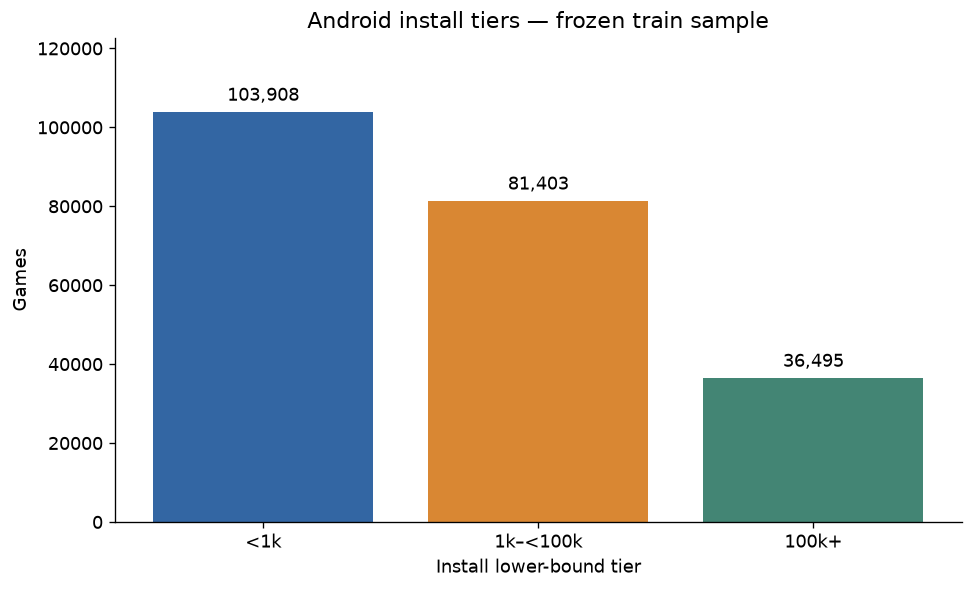

In [6]:
LABELS = ["M1_under_1k", "M2_1k_to_under_100k", "M3_100k_plus"]
SHORT = ["<1k", "1k–<100k", "100k+"]
COLORS = ["#3366A3", "#D98733", "#438574"]
tier_counts = df["target_tier"].value_counts().reindex(LABELS, fill_value=0)
tier_table = pd.DataFrame({"n": tier_counts, "pct": tier_counts / len(df) * 100})
assert tier_counts.tolist() == [103908, 81403, 36495]
display(tier_table.round(2))

fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
bars = ax.bar(SHORT, tier_counts.to_numpy(), color=COLORS)
ax.bar_label(bars, labels=[f"{n:,}" for n in tier_counts], padding=4)
ax.set(title="Android install tiers — frozen train sample", xlabel="Install lower-bound tier", ylabel="Games")
ax.set_ylim(0, tier_counts.max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(FIGURES / "01_install_tiers.png", dpi=180)
plt.show()

**自己解釋：**哪一級最多？若模型永遠猜最多的那級，accuracy 會是多少？這樣是否代表能辨識其他級別？

## 5. 用 groupby 比較組別
下面先計算每個免費狀態、每個 tier 的數量，再除以**該組總數**。這與把所有遊戲都作分母不同。

未知組只有 4 筆，保留在統計表，但不放進主要比較圖；不能用它作穩定結論。圖中的免費／付費差異是描述關聯，不是改成免費後的因果效果。

target_tier,M1_under_1k,M2_1k_to_under_100k,M3_100k_plus
free_group,,,
Free,101160,78722,36070
Paid,2746,2680,424
Unknown,2,1,1


target_tier,M1_under_1k,M2_1k_to_under_100k,M3_100k_plus
free_group,,,
Free,46.84,36.45,16.70
Paid,46.94,45.81,7.25
Unknown,50.00,25.00,25.00


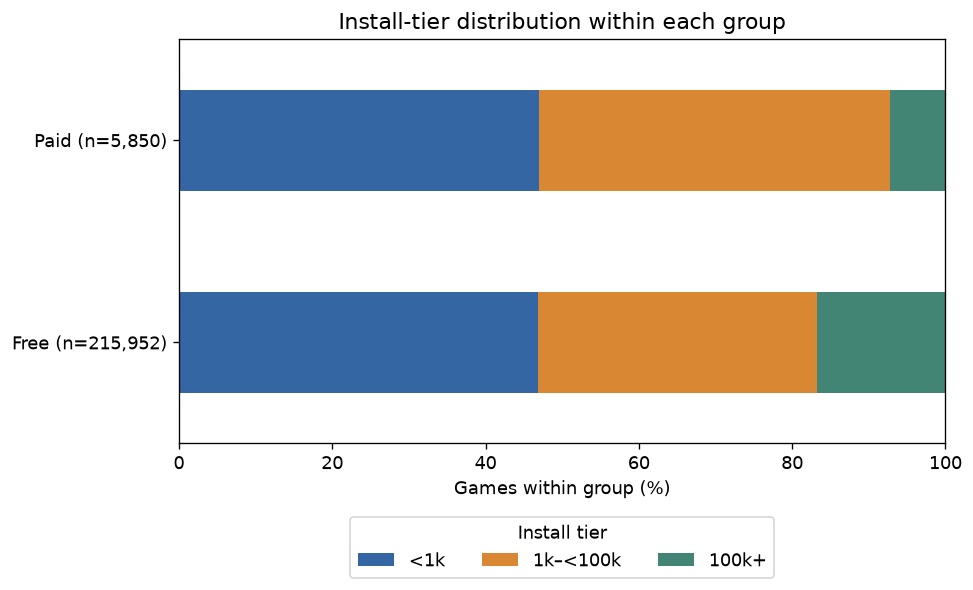

In [7]:
assert set(df["free"]) == {"Yes", "No", "Unknown"}
free_group = df["free"].map({"Yes": "Free", "No": "Paid", "Unknown": "Unknown"})
group_counts = df.assign(free_group=free_group).groupby(["free_group", "target_tier"], dropna=False).size().unstack(fill_value=0)
group_counts = group_counts.reindex(columns=LABELS, fill_value=0)
group_pct = group_counts.div(group_counts.sum(axis=1), axis=0) * 100
display(group_counts)
display(group_pct.round(2))

assert set(group_counts.index) == {"Free", "Paid", "Unknown"}
assert group_counts.sum(axis=1).to_dict() == {"Free": 215952, "Paid": 5850, "Unknown": 4}
shown = group_pct.loc[["Free", "Paid"]].copy()
shown.columns = SHORT
fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
shown.plot.barh(stacked=True, color=COLORS, ax=ax)
ax.set(title="Install-tier distribution within each group", xlabel="Games within group (%)", ylabel="")
ax.set_yticks([0, 1], ["Free (n=215,952)", "Paid (n=5,850)"])
ax.set_xlim(0, 100)
ax.legend(title="Install tier", loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
fig.savefig(FIGURES / "02_free_paid_tiers.png", dpi=180)
plt.show()

**練習 A（先完成這裡即可）：**另加一格，試試以下兩行，解釋每行用途：
```python
df.groupby("category").size().sort_values(ascending=False).head(10)
df.loc[df["category"] == "Puzzle", "target_tier"].value_counts()
```
不要直接修改來源 CSV。把自己的觀察寫在新的 Markdown cell；不能只把圖貼進報告。

## 6. 從展示資料轉到正式模型資料
CSV 方便閱讀；正式模型用 Parquet，保留欄位型別。模型還需要 developer groups 及固定 folds，這些沒有全部放在 Power BI CSV 內。

因此我們讀取研究的 features 與 **train-only labels/splits**，用 `merge()` 按 `app_id` 合併。這個動作不是重新切分，也不把 app 匯入的新資料混進研究。

In [8]:
features_path = verified_path(
    "data/processed/analysis_v1/mobile_features.parquet",
    analysis["outputs"]["data/processed/analysis_v1/mobile_features.parquet"])
labels_path = verified_path(
    "data/processed/analysis_v1/mobile_labels_splits.parquet",
    analysis["outputs"]["data/processed/analysis_v1/mobile_labels_splits.parquet"])

features = pd.read_parquet(features_path)
train_labels = pd.read_parquet(labels_path, filters=[("split", "==", "train")])
train = features.merge(train_labels, on="app_id", validate="one_to_one").sort_values("app_id").reset_index(drop=True)
assert len(train) == len(df) and set(train["app_id"]) == set(df["app_id"])
assert train["split"].eq("train").all()
assert np.array_equal(
    train["target_tier"].to_numpy(),
    df.set_index("app_id").loc[train["app_id"], "target_tier"].to_numpy())
del features
print("正式 train 與 CSV 是同一批遊戲：", len(train))
display(train[["app_id", "category", "free", "price_usd", "developer_group", "cv_fold", "target_tier"]].head())

正式 train 與 CSV 是同一批遊戲： 221806


,app_id,category,free,price_usd,developer_group,cv_fold,target_tier
0,BKE.blom.com,Puzzle,True,0.0,mobile_cfcf2004fa24b07de50e920f2fb7b65f69b1d9d...,0,M2_1k_to_under_100k
1,ExtremeDevelopers.Exorcist,Arcade,False,9.99,mobile_8da6ee8b29c34585d23c6a30fa93b5ba3066245...,0,M1_under_1k
2,ExtremeDevelopers.NeedforDrift,Racing,True,0.0,mobile_8da6ee8b29c34585d23c6a30fa93b5ba3066245...,0,M3_100k_plus
3,LASroCd.game,Arcade,True,0.0,mobile_fc80afb7427c23550358a46efafce85b5303ce4...,1,M1_under_1k
4,LiborVasa.Ships,Puzzle,True,0.0,mobile_4733fd3a79e6f2b00092faab054abb568dbc834...,2,M3_100k_plus


### X 是甚麼？y 是甚麼？
- `X`：模型可使用的遊戲屬性，例如類別、價格、廣告／內購設定。
- `y`：已知的安裝量級別，用來教模型及評分。
- `app_id`、developer 身分、安裝量及由 outcome 派生的 `tier_order` 等，不可當作預測輸入。

今天重現 **P 的 Logistic Regression**：它做分類，雖然名稱有 Regression。P 不包括觀察年齡；P+A 才會加入年齡。這些屬性仍是歷史快照，不等於已證明在上市前可取得。

In [9]:
policy = read_json(ROOT / "config/feature_policy_v1.json")
FEATURES = policy["mobile"]["P"]
assert not set(FEATURES) & set(policy["forbidden_predictors"])
X = train[FEATURES]
y = train["target_tier"]
print("X 欄位：", FEATURES)
print("X shape:", X.shape, "y shape:", y.shape)
display(X.head())

X 欄位： ['category', 'content_rating', 'free', 'price_usd', 'price_usd_unavailable', 'ad_supported', 'in_app_purchases', 'free_unavailable']
X shape: (221806, 8) y shape: (221806,)


,category,content_rating,free,price_usd,price_usd_unavailable,ad_supported,in_app_purchases,free_unavailable
0,Puzzle,Everyone,True,0.0,False,False,False,False
1,Arcade,Teen,False,9.99,False,False,False,False
2,Racing,Everyone,True,0.0,False,False,True,False
3,Arcade,Everyone,True,0.0,False,False,False,False
4,Puzzle,Everyone,True,0.0,False,False,False,False


## 7. 沿用固定的一折
正式研究在 train 內有三個 developer-group folds。今天只示範 **fold 0 作 validation，fold 1、2 作 fitting**。

這裡的 validation 仍屬研究的 train 分區；不是最後 test。相同 developer group 不可同時出現在兩邊。先看分組，再做補值及編碼，避免從 validation 學到資訊。

In [10]:
FOLD = 0
fit_rows = train.loc[train["cv_fold"] != FOLD]
valid_rows = train.loc[train["cv_fold"] == FOLD]
X_fit, y_fit = fit_rows[FEATURES], fit_rows["target_tier"]
X_valid, y_valid = valid_rows[FEATURES], valid_rows["target_tier"]

assert len(X_fit) == 147902 and len(X_valid) == 73904
assert set(fit_rows["developer_group"]).isdisjoint(valid_rows["developer_group"])
assert set(fit_rows["app_id"]).isdisjoint(valid_rows["app_id"])
assert train.groupby("developer_group")["cv_fold"].nunique().max() == 1
print("Fitting:", len(X_fit), "Validation:", len(X_valid))
display(pd.DataFrame({"fitting": y_fit.value_counts(), "validation": y_valid.value_counts()}).reindex(LABELS))

Fitting: 147902 Validation: 73904


,fitting,validation
target_tier,,
M1_under_1k,69494,34414
M2_1k_to_under_100k,54274,27129
M3_100k_plus,24134,12361


## 8. 前處理：fit 與 transform 有何分別？
這次使用既有的 `PlanningEncoder`，令教學與正式研究採用同一規則：
1. 價格做 log1p；缺失值用 fitting rows 的中位數填補，另保留缺失旗標。
2. 數值使用 fitting rows 的平均值／標準差縮放。
3. 類別轉成數字欄位；未知布林值保留獨立類別。
4. validation 只做 `transform`，使用已學好的規則。

`fit_transform(X_fit)` 是學規則再轉換；`transform(X_valid)` 只套用規則。請打開 `src/models/preprocessing.py`，找出 `fit()`、`transform()` 和 `numeric_stats_`。

In [11]:
model_source = ROOT / "src/models"
if str(model_source) not in sys.path:
    sys.path.insert(0, str(model_source))
from preprocessing import PlanningEncoder

encoder = PlanningEncoder("mobile", "P")
X_fit_encoded = encoder.fit_transform(X_fit)
X_valid_encoded = encoder.transform(X_valid)
print("編碼後：", X_fit_encoded.shape, X_valid_encoded.shape)
display(pd.DataFrame(encoder.numeric_stats_).T)
print("前 8 個編碼欄位：", encoder.get_feature_names_out()[:8].tolist())
print("Validation 未見類別覆蓋：", encoder.coverage(X_valid))
# 只展示前 3 列、8 欄，避免把整個稀疏矩陣變成大型 dense table。
display(pd.DataFrame(X_fit_encoded[:3, :8].toarray()))

編碼後： (147902, 35) (73904, 35)


,median,mean,std
price_usd,0.0,0.033677,0.225564


前 8 個編碼欄位： ['["category","ad_supported","False"]', '["category","ad_supported","True"]', '["category","category","Action"]', '["category","category","Adventure"]', '["category","category","Arcade"]', '["category","category","Board"]', '["category","category","Card"]', '["category","category","Casino"]']
Validation 未見類別覆蓋： {'validation_rows': 73904, 'rows_with_unknown': 0, 'encoded_keys': 665136, 'unknown_keys': 0, 'unknown_by_column': {}}


,0,1,2,3,4,5,6,7
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


## 9. 真正訓練一次模型
`.fit()` 才是這一格的訓練動作；`.predict_proba()` 產生每一類的模型機率。它們尚未校準，不能直接當成新遊戲的成功機率。

參數沿用既有 `P_C0.1_none`，不在這份教學重新搜尋。一般需要數十秒，實際時間視電腦而定。先執行，不要同時重按多次。

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning

config = read_json(ROOT / "config/model_dev_v1.json")
model = LogisticRegression(
    C=0.1, class_weight=None, solver=config["solver"], l1_ratio=config["l1_ratio"],
    max_iter=config["max_iter"], tol=config["tol"], random_state=config["seed"])
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    with threadpool_limits(limits=2):
        model.fit(X_fit_encoded, y_fit)
        probabilities = model.predict_proba(X_valid_encoded)
assert model.classes_.tolist() == LABELS
predicted = model.classes_[probabilities.argmax(axis=1)]

baseline = DummyClassifier(strategy="prior")
baseline.fit(np.zeros((len(y_fit), 1)), y_fit)
baseline_prediction = baseline.predict(np.zeros((len(y_valid), 1)))
print("訓練完成；validation 預測筆數：", len(predicted))
display(pd.DataFrame(probabilities[:5], columns=SHORT))
print("每列機率總和：", probabilities[:5].sum(axis=1))

訓練完成；validation 預測筆數： 73904


,<1k,1k–<100k,100k+
0,0.736161,0.234971,0.028868
1,0.460447,0.510469,0.029083
2,0.347494,0.355454,0.297052
3,0.736161,0.234971,0.028868
4,0.553059,0.371542,0.075399


每列機率總和： [1. 1. 1. 1. 1.]


### 評估：accuracy 並非唯一指標
- Accuracy：全部 validation 遊戲中，猜對多少比例。
- Macro-F1：先算每級 F1，再給每級相同權重，避免只看最多的那級。
- Balanced accuracy：各真實類別召回率的平均。
- Class-prior baseline：依 fitting 分布產生機率，選最高者時就是一直猜最多的類別。

下面是**同一折**的教學比較。正式研究的主要比較用三折平均，這裡的分數不是三折平均，也不是獨立最終成績。

In [13]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report

def evaluate(name, prediction):
    return {"model": name,
            "accuracy": accuracy_score(y_valid, prediction),
            "balanced_accuracy": balanced_accuracy_score(y_valid, prediction),
            "macro_f1": f1_score(y_valid, prediction, labels=LABELS, average="macro", zero_division=0)}

scores = pd.DataFrame([
    evaluate("Class-prior baseline", baseline_prediction),
    evaluate("Logistic Regression P", predicted)
]).set_index("model")
display(scores.round(4))
print(classification_report(y_valid, predicted, labels=LABELS, target_names=SHORT, digits=4, zero_division=0))

,accuracy,balanced_accuracy,macro_f1
model,,,
Class-prior baseline,0.4657,0.3333,0.2118
Logistic Regression P,0.5564,0.4744,0.4775


              precision    recall  f1-score   support

         <1k     0.6055    0.8068    0.6918     34414
    1k–<100k     0.4658    0.3884    0.4236     27129
       100k+     0.5196    0.2281    0.3170     12361

    accuracy                         0.5564     73904
   macro avg     0.5303    0.4744    0.4775     73904
weighted avg     0.5399    0.5564    0.5307     73904



### 生成第三張圖：混淆矩陣
每一列代表真實類別，每一欄代表模型預測；各列加起來為 1。對角線就是該類召回率。

自己回答：哪一級最容易被模型漏掉？即使總 accuracy 高於 baseline，是否仍有弱點？

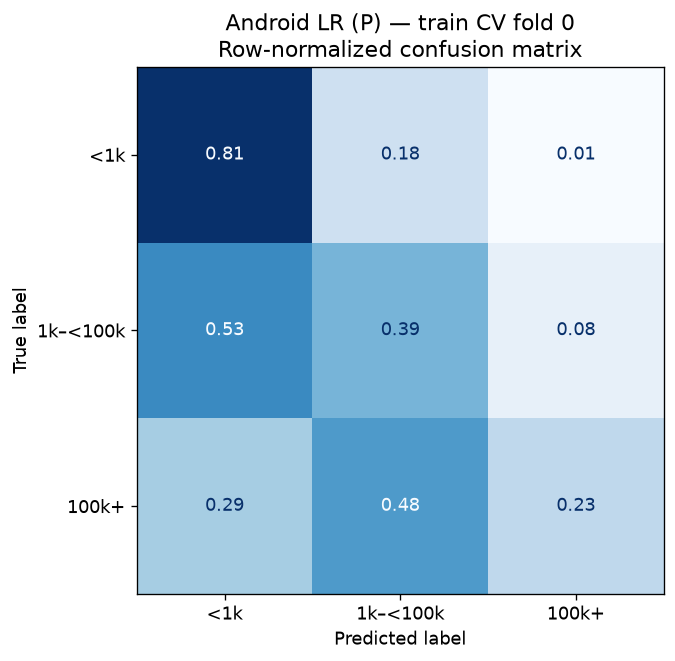

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, ax = plt.subplots(figsize=(7, 5.4), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_valid, predicted, labels=LABELS, display_labels=SHORT,
    normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Android LR (P) — train CV fold 0\nRow-normalized confusion matrix")
fig.savefig(FIGURES / "03_confusion_matrix.png", dpi=180)
plt.show()
cm = confusion_matrix(y_valid, predicted, labels=LABELS)
assert cm.sum() == len(y_valid)
assert np.isclose(np.trace(cm) / cm.sum(), scores.loc["Logistic Regression P", "accuracy"])

## 10. 與正式研究對照
最後讀取既有同一折的 OOF（out-of-fold）預測，按 ID 對齊。新訓練結果應在數值精度內一致。

這個檢查用來確認「你剛執行的程式確實重現已有研究」，並不是額外的泛化測試。Notebook 不會儲存或取代正式模型。

In [14]:
source_manifest_relative = "reports/2026-10-07/model_dev_v1/run_manifest.json"
source_manifest = read_json(verified_path(
    source_manifest_relative,
    "e7384e173bbac967183d4e332ced50158021fd454dc1e5c760e49847edf3af16"))
for relative, expected_hash in source_manifest["identity"]["dependencies"].items():
    verified_path(relative, expected_hash)
pred_relative = "data/processed/model_dev_v1/mobile__P_C0.1_none__fold0.parquet"
reference = pd.read_parquet(verified_path(pred_relative, source_manifest["artifacts"][pred_relative]))
assert reference["app_id"].is_unique
reference = reference.set_index("app_id").loc[valid_rows["app_id"]]
assert np.array_equal(reference["target_tier"], y_valid)
assert np.array_equal(reference["developer_group"], valid_rows["developer_group"])
assert reference["cv_fold"].eq(FOLD).all()
max_difference = float(np.abs(probabilities - reference[["p0", "p1", "p2"]].to_numpy()).max())
assert np.allclose(probabilities, reference[["p0", "p1", "p2"]].to_numpy(), atol=1e-10, rtol=1e-10)
print("與正式預測的最大機率差：", max_difference)

assert all(sha256(ROOT / relative) == expected for relative, expected in guarded.items())
summary = {
    "purpose": "student walkthrough; one existing development fold reproduced",
    "csv_rows": len(df), "fit_rows": len(X_fit), "validation_rows": len(X_valid),
    "developer_group_overlap": 0, "max_probability_difference": max_difference,
    "scores": scores.reset_index().to_dict(orient="records"),
    "calibration_evaluated": False, "test_evaluated": False,
    "guarded_inputs_unchanged": len(guarded),
    "figures": {p.name: sha256(p) for p in sorted(FIGURES.glob("*.png"))}
}
(OUT / "execution_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("完成！三張圖及教學摘要位於：", OUT)

與正式預測的最大機率差： 0.0
完成！三張圖及教學摘要位於： F:\HKBU_Y4\FYP\My_FYP\Program\reports\2026-10-16\walkthrough_v1


## 11. 對照正式程式，以及自己接手的練習

| 今天做的事 | 正式程式（相對 Program） |
|---|---|
| 原始資料清理與標籤建立（今天使用清理後資料） | `src/data/clean_candidates.py`、`cleaning_rules.py` |
| Pandas 讀 CSV | `src/analysis/export_powerbi_v1.py` 負責生成這份 CSV |
| 統計分布／分組 | `src/analysis/profile_training.py`（正式版本使用 DuckDB 查詢） |
| 特徵、補值、編碼 | `config/feature_policy_v1.json`、`src/models/preprocessing.py` |
| Logistic Regression 與三折比較 | `src/models/run_development.py` |
| Random Forest | `src/models/run_tree_development.py` |
| cohort／target 敏感度 | `src/models/run_scope_sensitivity.py` |
| 使用者匯入 CSV 及比較介面 | `src/imports/`、`src/demo/` |

**練習 B：**在 Notebook 加一格，畫出年齡（`age_days / 365.25`）的直方圖。先檢查缺失及範圍；圖上說明是歷史觀察年齡。

**練習 C：**用自己的文字回答：
1. 為何 `tier_order` 不能放進 X？
2. 為何前處理只能對 X_fit 做 fit？
3. 為何按 developer group 分開？
4. 第一張圖的比例與第二張圖的比例，分母有何不同？
5. 這個模型是否可以聲稱能預測新遊戲的收入？理由是甚麼？

本輪先不增加 KNN／K-means 或重調參數。日後的相似遊戲參考可以討論 nearest-neighbour 思路；它與今天的三級分類是不同功能。模型研究下一個待辦仍是另行預先訂定的 group-versus-random 對照。

**完成標準：**你能親手從頭執行、解釋三張圖、指出 X/y 及 fitting/validation 的分別，並至少完成一項自己的練習。請保留自己的解釋及修改紀錄。